## PyTorch Computer Vision 

**torchvision** --> Contains datasets, model architectures and image transformations often used for computer vision problems.

**torchvision.datasets** --> Here you'll find many example computer vision datasets for a range of problems from image classification, object detection, image captioning, video classification and more. It also contains a series of base classes for making custom datasets.

**torchvision.models** -->	This module contains well-performing and commonly used computer vision model architectures implemented in PyTorch, you can use these with your own problems.

**torchvision.transforms** -->	Often images need to be transformed (turned into numbers/processed/augmented) before being used with a model, common image transformations are found here.

**torch.utils.data.Dataset** --> Base dataset class for PyTorch.
**torch.utils.data.DataLoader** -->	Creates a Python iterable over a dataset (created with torch.utils.data.Dataset).

**ToTensor** --> Converts a PIL Image or numpy.ndarray (H x W x C) in the range [0, 255] to a torch.FloatTensor of shape (C x H x W) in the range [0.0, 1.0] if the PIL Image belongs to one of the modes (L, LA, P, I, F, RGB, YCbCr, RGBA, CMYK, 1) or if the numpy.ndarray has dtype = np.uint8

In [27]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset

import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor


from helper_functions import accuracy_fn


import matplotlib.pyplot as plt 
import requests

from tqdm.auto import tqdm ## for progress bar

from pathlib import Path

print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


In [2]:
## Download helper functions from Learn PyTorch repo

if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download...")

else:
    print("Download helper_functions.py")

    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")

    with open("helper_functions.py", "wb") as f:
        f.write(requests.content)

helper_functions.py already exists, skipping download...


### Getting a Dataset

The dataset we'll be using is FashionMINIST from `torchvision.datasets`



In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform= ToTensor(),
    target_transform=None
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [4]:
len(train_data), len(test_data)

(60000, 10000)

In [5]:
class_name = test_data.classes

print("Class\n", class_name)



Class
 ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [6]:
## Check Image Shape 
image , lable = train_data[0]
print("Image Shape: ", image.shape)
print("Image labels: ", class_name[lable])

Image Shape:  torch.Size([1, 28, 28])
Image labels:  Ankle boot


### Visualizing Data 



(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

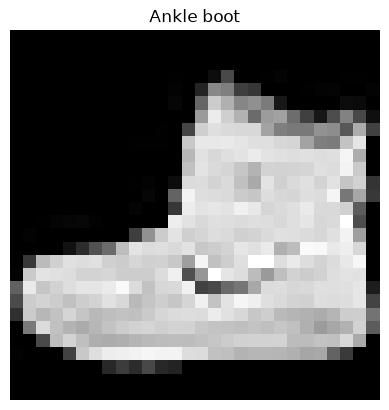

In [7]:
image, lable = train_data[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_name[lable])
plt.axis(False)

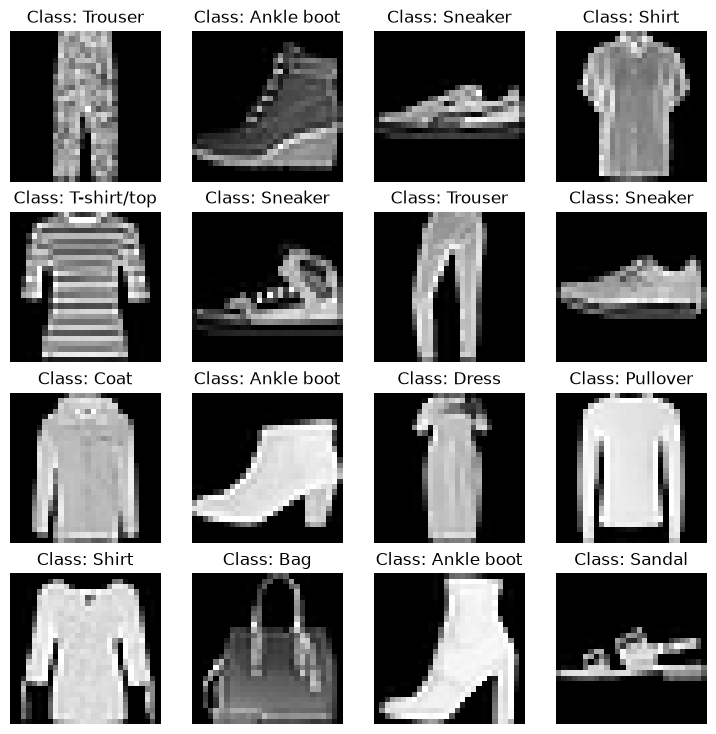

In [8]:
# Visualize More Image


torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))

rows, cols = 4, 4

for i in range(1, rows*cols+1):
    random_index = torch.randint(0, len(test_data), size=[1]).item()
    image, label= train_data[random_index]

    fig.add_subplot(rows, cols, i)

    plt.imshow(image.squeeze(), cmap="gray")

    plt.title(f"Class: {class_name[label]}")

    plt.axis(False);

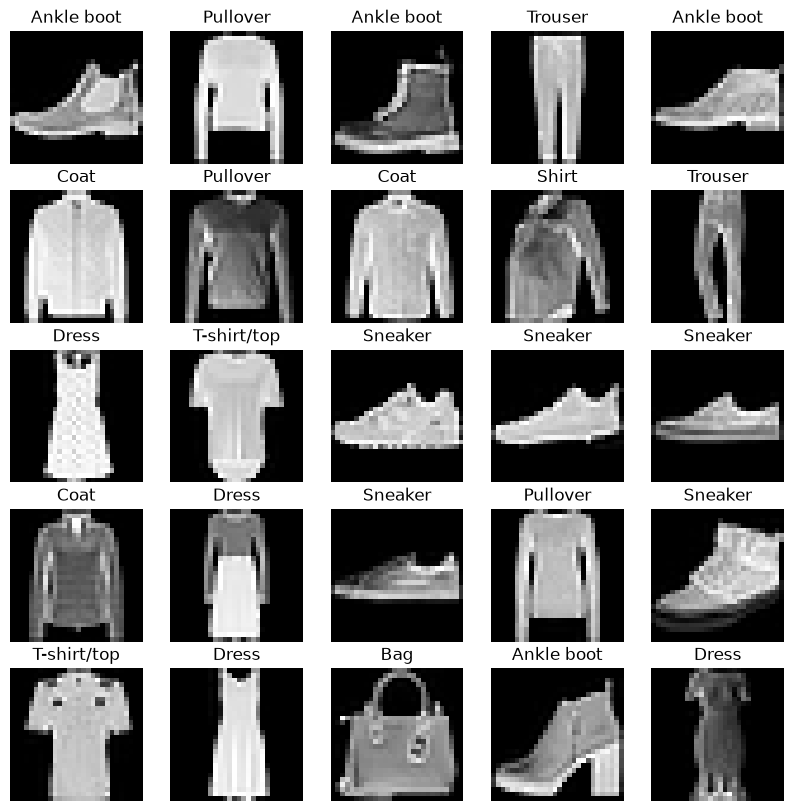

In [9]:
### Now Visualize without random seed.

fig = plt.figure(figsize=(10, 10))

rows, cols = 5, 5

for i in range(1, rows*cols+1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()

    img, lab = train_data[random_idx]

    fig.add_subplot(rows, cols, i)

    plt.imshow(img.squeeze(), cmap="gray")

    plt.title(class_name[lab])

    plt.axis(False);

In [10]:
train_data, test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [11]:
train_loader = DataLoader(dataset=train_data,
                          batch_size=32,
                          shuffle=True)

test_loader = DataLoader(dataset=test_data,
                         batch_size=32,
                         shuffle=False)


In [12]:
## Let's check out what what we've created 

print(f"DataLoader: {train_loader, test_loader}")

print(f"Length of train dataloader: {len(train_loader)}")
print(f"Length of test dataloader: {len(test_loader)}")

DataLoader: (<torch.utils.data.dataloader.DataLoader object at 0x7895d3600690>, <torch.utils.data.dataloader.DataLoader object at 0x7895e40fa790>)
Length of train dataloader: 1875
Length of test dataloader: 313


In [13]:
## Check out what's inside the training dataloader

train_features_batch, train_labels_batch = next(iter(train_loader))

train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: Sandal


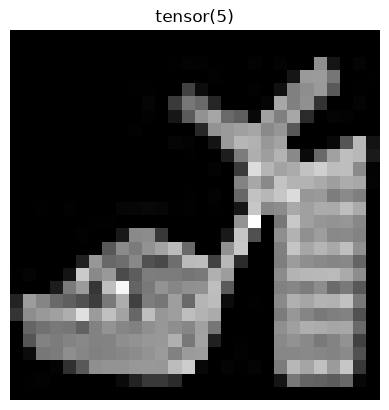

In [14]:
# show a sample 

torch.manual_seed(42)

random_id = torch.randint(0 , len(train_features_batch), size=[1]).item()

img, labels = train_features_batch[random_id], train_labels_batch[random_id]

plt.imshow(img.squeeze(), cmap="gray")

plt.title(labels)

plt.axis(False);

print(f"Image size: {img.shape}")
print(f"Label: {class_name[labels]}")

### Create Model Using nn.Module and nn.Sequential

### Model 0: Build a basline model

##### When starting to build a series of mahine learning modelling experiments, it's best practice to start with a baseline model. A baseline model is a simple model you will try and improve upon with subsequent models/experiments.
##### In other words: start simply and add complexity when necessary.

In [15]:
# Create a flatten layer 

flatten_model = nn.Flatten()

# get a single sample 

x = train_features_batch[0]

# Flatten the sample 

output = flatten_model(x) # perform forward pass

print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} -> [color_channels, height*width]")

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


In [16]:
class FashionMINISTModelV0(nn.Module):
    def __init__(self, 
                 input_shape: int,
                 hidden_units: int,
                 output_shape: int):
        super().__init__()

        self.layer_stack = nn.Sequential(
            nn.Flatten(),

            nn.Linear(in_features=input_shape,
                      out_features=hidden_units),

            nn.Linear(hidden_units, output_shape)

        )

    def forward (self, x):
        return self.layer_stack(x)

In [17]:
torch.manual_seed(42)

model_0 = FashionMINISTModelV0(
    input_shape=784, # 28*28
    hidden_units= 10,
    output_shape=len(class_name)
   
)

In [18]:
dummy_x = torch.rand([1, 1, 28, 28])

model_0(dummy_x)


tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [19]:
# Calculate Accuracy 

# def accuracy_fn(y_true= None, y_preds= None):
#     correct = torch.eq(y_true, y_preds).sum().item()

#     acc = (correct/len(y_preds)) * 100 

#     return acc

In [21]:
lo_fn = nn.CrossEntropyLoss()

op = optim.Adam(params=model_0.parameters(),
                lr=0.001)



## Creating a function to time our experiments 

Machine learning is very experimental.

Two of the main things will often want to track are:
1. Model's performance(loss and accuracy values etc)
2. How fast it runs 

In [24]:
next(model_0.parameters()).device

device(type='cpu')

In [25]:
from timeit import default_timer  as timer 

def print_train_time(start: float,
                     end: float ,
                     device: torch.device = None):
    """Prints difference between start and end time."""

    total_time =  end - start

    print(f"Train time on {device}: {total_time:.3f} seconds")

    return total_time

In [ ]:
start_time = timer()

# some code ....

end_time = timer()

print_train_time(start=start_time, end=end_time, device="cpu")

Train time on cpu: 0.000 seconds


9.166999916487839e-06

#### Creating a training loop and training the data in batches.

In [33]:
torch.manual_seed(42)

train_time_start =  timer()


# set the number of epochs 

epochs = 3

# create training and test loop 

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n_____")

    ## Training 

    train_loss = 0

    # Add a loop to loop through the training batches 

    for batch, (x, y) in enumerate(train_loader):
        model_0.train()

        y_pred = model_0(x)

        # calculate loss per batch
        loss =  lo_fn(y_pred, y)

        train_loss += loss

        op.zero_grad()

        loss.backward()

        op.step()

        if batch % 400 == 0:
            print(f"Looked at {batch * len(x)}/{len(train_loader.dataset)} samples.")


    train_loss /= len(train_loader)


#### Testing 

test_loss, test_acc = 0, 0

model_0.eval()

with torch.inference_mode():
    for X_test, Y_test in test_loader:
        test_pred =  model_0(X_test)

        loss = lo_fn(test_pred, Y_test)

        test_loss += loss

        # calculate accuracy 

        test_acc += accuracy_fn(y_true=Y_test, y_pred=test_pred.argmax(dim=1))

    test_loss /= len(test_loader)

    test_acc /= len(test_loader)


print(f"\nTrain loss: {train_loss: .2f} || Test loss: {test_loss: .2f} || Test Accuracy: {test_acc}")

train_end_time = timer()

total_train_time = print_train_time(start=train_time_start, end=train_end_time,
                                    device=str(next(model_0.parameters()).device))

      



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Epoch: 1
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Epoch: 2
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss:  0.40 || Test loss:  0.47 || Test Accuracy: 83.53634185303514
Train time on cpu: 6.966 seconds


## Make predictions and get Model 0 Results

In [36]:
torch.manual_seed(42)

def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn = torch.nn.Module,
               acc = accuracy_fn):
    """Returns a dictionary containing the results of model predicting on data_loader.."""

    Test_loss, acc = 0, 0

    model.eval()
    with torch.inference_mode():
        for X, Y in tqdm(data_loader):
            Y_pred = model(X)

            loss = loss_fn(Y_pred, Y)

            Test_loss += loss

            acc += accuracy_fn(y_true=Y,
                               y_pred=Y_pred.argmax(dim=1))

        Test_loss /= len(data_loader)

        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
            "model_loss": Test_loss.item(),
            "ModelAccuracy": acc}


model_0_results = eval_model(model=model_0,
                             data_loader=test_loader,
                             loss_fn= lo_fn,
                             acc=accuracy_fn)

model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMINISTModelV0',
 'model_loss': 0.46751904487609863,
 'ModelAccuracy': 83.53634185303514}